# LoRA
IndoBERT (`indobenchmark/indobert-base-p2`) | data sizes 10 / 50 / 100% | 5 seeds.

Configuration: **r=8, alpha=16, lr=2e-4**, targeting the query/value projections. **lora_dropout=0.1**

In [ ]:
!pip install -q transformers==4.57.6 peft==0.18.1, datasets==5.0.1, accelerate==1.14.0
!pip install -q -U scikit-learn

import transformers, datasets, peft, accelerate, torch
print("transformers:", transformers.__version__, " (pinned)")
print("peft        :", peft.__version__, " (pinned)")
print("datasets    :", datasets.__version__, " (pinned)")
print("accelerate  :", accelerate.__version__, " (pinned)")
print("torch       :", torch.__version__, " (Colab-provided)")
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), " <- keep the same GPU type across methods")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 68.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.27.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/code')   # folder containing utils.py
from utils import *

print("Data root    :", DATA_ROOT)
print("Results file :", RESULTS_PATH)
print("Seeds        :", SEEDS)
print("Data sizes   :", DATA_SIZES)

Mounted at /content/drive
Data root    : /content/drive/MyDrive/thesis/data
Results file : /content/drive/MyDrive/thesis/results.csv
Seeds        : [42, 123, 456, 789, 2026]
Data sizes   : [100, 50, 10]


### Check data and progress

In [ ]:
validate_data_sizes()
print()
print_status()

 size_%                                folder  rows  actual_%_of_full  hoax_%
     10 /content/drive/MyDrive/thesis/data/10   848              10.0    50.0
     50 /content/drive/MyDrive/thesis/data/50  4244              50.0    50.0
    100    /content/drive/MyDrive/thesis/data  8486             100.0    50.0

val rows: 1212 | test rows: 2426 | full train rows: 8486
evaluation interval (steps per full-data epoch): 531
Data checks passed.

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
FFT          5    5    5
Total: 15 / 15 for methods present


### Model definition

In [5]:
from peft import LoraConfig, get_peft_model, TaskType

LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.1

def build_lora_model():
    base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
    )
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=["query", "value"],
        bias="none",
    )
    model = get_peft_model(base, lora_config)
    model.print_trainable_parameters()
    return model

### Run all data sizes and seeds

In [ ]:
METHOD_NAME = "LoRA"
LEARNING_RATE = 2e-4
TAG = "main"             
RUN_SIZES = DATA_SIZES
RUN_SEEDS = SEEDS

In [7]:
for size in RUN_SIZES:
    for seed in RUN_SEEDS:
        run_experiment(
            method_name=METHOD_NAME,
            seed=seed,
            model_init_fn=build_lora_model,
            learning_rate=LEARNING_RATE,
            data_size=size,
            tag=TAG,
        )

print()
print_status(tag=TAG)


  LoRA | data 100% | seed 42 | tag main | lr 0.0002


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (118 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 296,450 || all params: 124,739,332 || trainable%: 0.2377
trainable parameters: 296,450 / 124,739,332 (0.2377%)


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
531,0.232700,0.560062,0.864686,0.865084,0.864686,0.864650
1062,0.033300,0.709015,0.872112,0.872235,0.872112,0.872102
1593,0.017600,0.746433,0.868812,0.869545,0.868812,0.868747
2124,0.015900,0.827642,0.867162,0.868004,0.867162,0.867086
2655,0.011400,0.804841,0.872937,0.873429,0.872937,0.872895



TEST -- Acc 0.8578 | F1 0.8577 | val F1 0.8729 | VRAM 0.763 GB | 2.9 min | 2655 steps (5 evals, best @ step 2655)

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
FFT          5    5    5
LoRA         5    5    5
Total: 30 / 30 for methods present


### Training curves
One seed per data size (the first in `RUN_SEEDS`). X-axis is the training step; the dashed line marks the checkpoint restored for test evaluation.

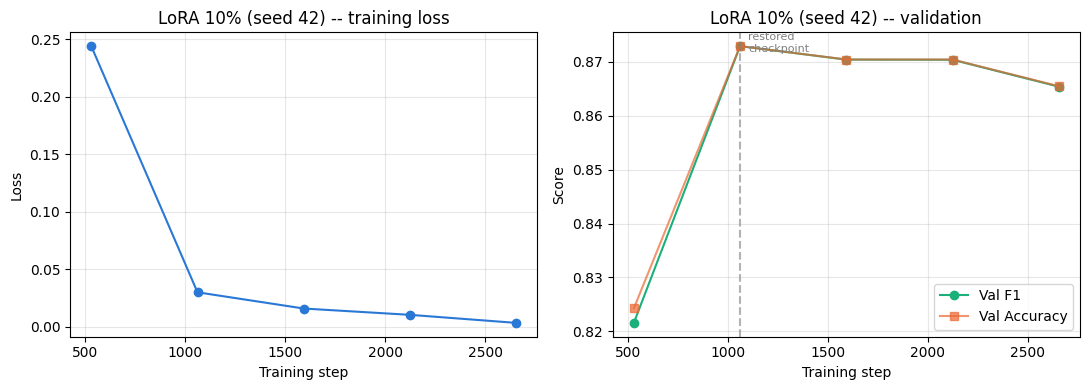

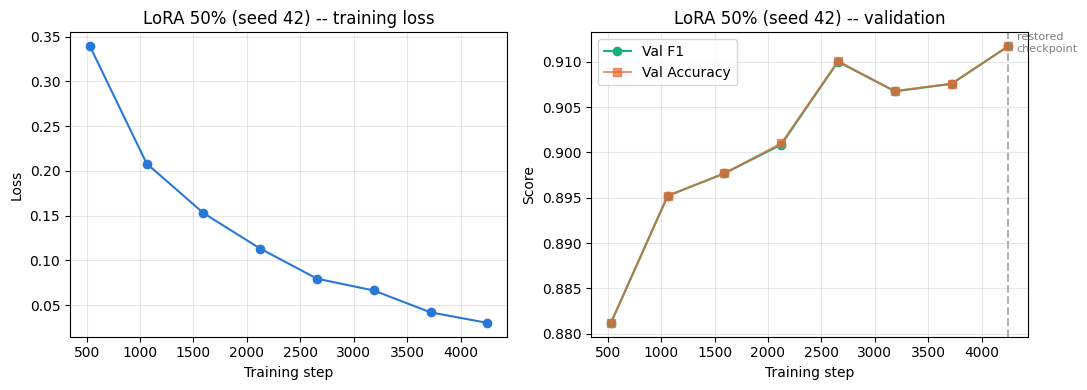

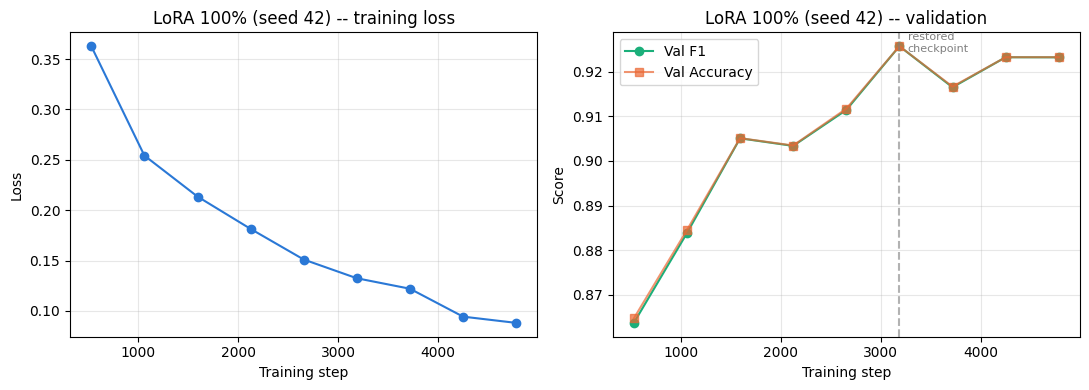

In [8]:
for size in sorted(RUN_SIZES):
    plot_training_curves(METHOD_NAME, RUN_SEEDS[0], size, TAG)

### Consistency across seeds
Validation F1 for all seeds overlaid, one chart per data size.

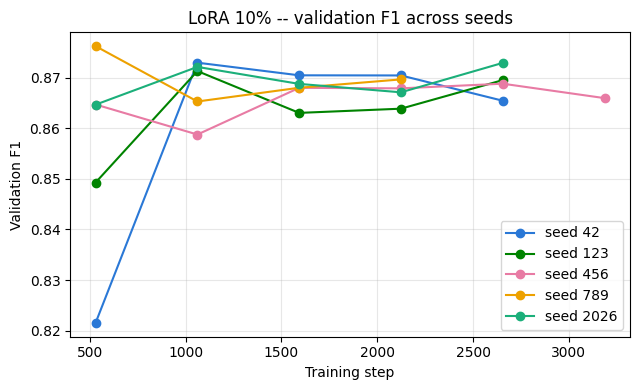

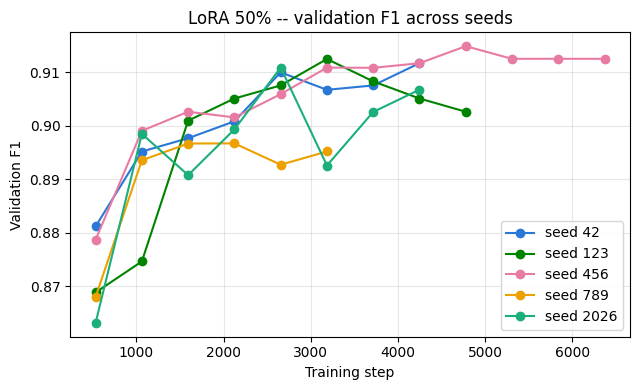

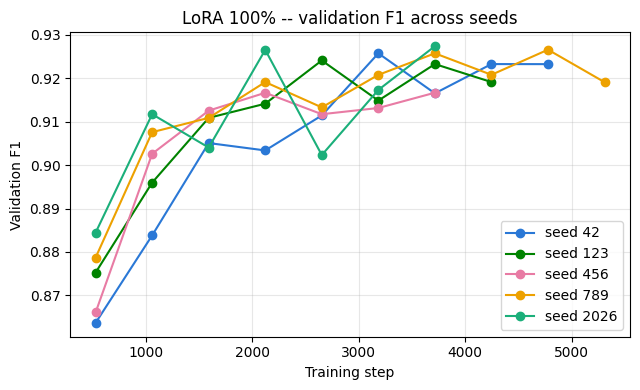

In [9]:
for size in sorted(RUN_SIZES):
    plot_seeds_overlay(METHOD_NAME, size, tag=TAG)

### Confusion matrices
Pooled over seeds, one per data size.

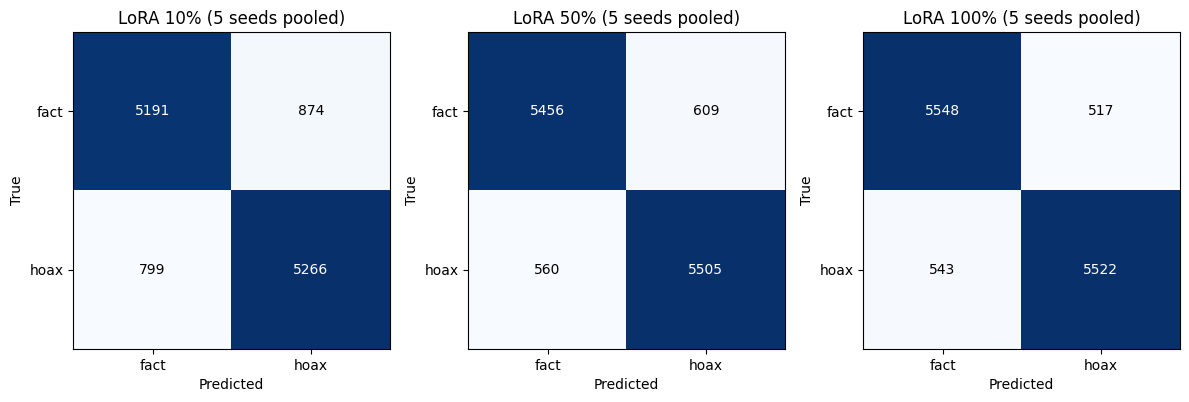

In [10]:
plot_confusion_matrices_by_size(METHOD_NAME, tag=TAG)

### Summary by data size
Mean +/- std over seeds: test vs. validation F1, generalization gap, training time.

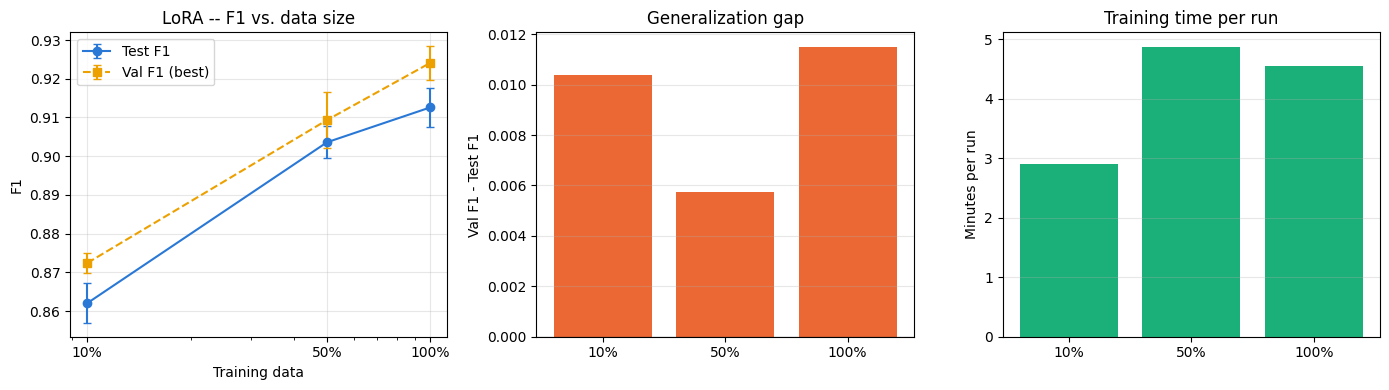

 data_size  seed  best_val_f1  accuracy       f1  trainable_pct  peak_vram_gb  total_time_s  epochs_run  steps_run
        10    42       0.8729  0.866859 0.866852         0.2377         0.763         173.8           5       2655
        10   123       0.8713  0.861500 0.861489         0.2377         0.763         173.3           5       2655
        10   456       0.8688  0.867683 0.867649         0.2377         0.763         208.7           6       3186
        10   789       0.8762  0.856554 0.856546         0.2377         0.763         139.3           4       2124
        10  2026       0.8729  0.857791 0.857712         0.2377         0.763         173.5           5       2655
        50    42       0.9117  0.909316 0.909315         0.2377         0.848         273.6           8       4248
        50   123       0.9125  0.903957 0.903918         0.2377         0.848         310.6           9       4779
        50   456       0.9149  0.905194 0.905168         0.2377         0.848   

In [11]:
plot_method_summary(METHOD_NAME, tag=TAG)